# Age and Topic Analysis Pipeline

This notebook:
1. Extracts age and topic data from Amazon books dataset
2. Matches with YouTube storyline transcripts
3. Cleans transcripts
4. Uses GPT-4 for event segmentation
5. Runs BERTopic on segmented events
6. Tunes hyperparameters for optimal topic modeling
7. Analyzes if topics can predict age


In [ ]:
import pandas as pd
import numpy as np
import re
from typing import List, Dict, Tuple
from tqdm import tqdm
import json
import os
from collections import Counter
import warnings
warnings.filterwarnings('ignore')

# Set random seed for reproducibility
np.random.seed(42)


## 1. Load and Merge Datasets


In [ ]:
# Load Amazon data
amazon_df = pd.read_csv('../data/amazon_data.csv')
print(f"Amazon data shape: {amazon_df.shape}")
print(f"Amazon columns: {amazon_df.columns.tolist()}")
print("\nSample Reading Age values:")
print(amazon_df['Reading Age'].head(10).tolist())

# Load YouTube transcripts
youtube_df = pd.read_excel('../data/youtube_storyline_transcripts.xlsx')
print(f"\nYouTube data shape: {youtube_df.shape}")
print(f"YouTube columns: {youtube_df.columns.tolist()}")
print("\nSample titles:")
print(youtube_df['title'].head(5).tolist())


Amazon data shape: (2766, 16)
Amazon columns: ['Book Title', 'Author', 'Publisher', 'Published Date', 'Categories (Amazon)', 'Categories (Google Books)', 'Summary', 'Reading Age', 'Print Length', 'ISBN-10', 'ISBN-13', 'Average Rating', 'Number of Reviews', 'Price (in USD)', 'Customer Review Count', 'Customer Age Distribution']

Sample Reading Age values:
['2 - 5 years, from customers', '3 - 5 years, from customers', '2 - 7 years, from customers', nan, '7 - 11 years, from customers', nan, '5 - 6 years, from customers', nan, nan, 'Baby - 2 years, from customers']

YouTube data shape: (95, 16)
YouTube columns: ['video_id', 'webpage_url', 'title', 'upload_date', 'duration_seconds', 'view_count', 'like_count', 'comment_count', 'channel', 'channel_url', 'uploader', 'description', 'tags', 'categories', 'thumbnail_url', 'cleaned_subtitles']

Sample titles:
["Calvin Can't Fly' read by Jonathan Pryce", "Carla's Glasses' read by Nicola Coughlan", "The Rooster Who Would Not Be Quiet!' read by Anna

In [ ]:
def extract_age_range(age_str):
    """Extract age range from various formats in Reading Age column"""
    if pd.isna(age_str) or age_str == 'N/A':
        return None, None
    
    age_str = str(age_str).lower()
    
    # Pattern: "2 - 5 years" or "2-5 years"
    match = re.search(r'(\d+)\s*-\s*(\d+)\s*years?', age_str)
    if match:
        return int(match.group(1)), int(match.group(2))
    
    # Pattern: "Baby - 2 years"
    match = re.search(r'baby\s*-\s*(\d+)\s*years?', age_str)
    if match:
        return 0, int(match.group(1))
    
    return None, None

def extract_customer_age_distribution(age_dist_str):
    """Extract age distribution from customer reviews"""
    if pd.isna(age_dist_str) or age_dist_str == '{}' or age_dist_str == '':
        return None
    
    try:
        if isinstance(age_dist_str, str):
            age_dict = eval(age_dist_str)
        else:
            age_dict = age_dist_str
        
        if isinstance(age_dict, dict) and age_dict:
            # Get the age with highest count
            max_age = max(age_dict.items(), key=lambda x: int(x[1]) if str(x[1]).isdigit() else 0)
            age_str = max_age[0]
            
            # Extract numeric age
            match = re.search(r'(\d+)', age_str)
            if match:
                return int(match.group(1))
    except:
        pass
    
    return None

# Process Amazon data
amazon_df['age_min'], amazon_df['age_max'] = zip(*amazon_df['Reading Age'].apply(extract_age_range))
amazon_df['customer_age_peak'] = amazon_df['Customer Age Distribution'].apply(extract_customer_age_distribution)

# Create a target age (use midpoint if range exists, otherwise use customer peak)
amazon_df['target_age'] = amazon_df.apply(
    lambda x: (x['age_min'] + x['age_max']) / 2 if pd.notna(x['age_min']) and pd.notna(x['age_max']) 
    else x['customer_age_peak'], axis=1
)

# Extract categories
amazon_df['categories_list'] = amazon_df['Categories (Amazon)'].apply(
    lambda x: x.split(' > ') if pd.notna(x) else []
)

print(f"\nAge statistics:")
print(amazon_df['target_age'].describe())
print(f"\nBooks with valid age: {amazon_df['target_age'].notna().sum()}")



Age statistics:


count    2397.000000
mean        7.021068
std         3.195996
min         0.500000
25%         4.500000
50%         7.000000
75%         9.500000
max        15.500000
Name: target_age, dtype: float64

Books with valid age: 2397


In [ ]:
def normalize_title(title):
    """Normalize titles for matching"""
    if pd.isna(title):
        return ""
    title = str(title).lower()
    # Remove special characters and extra spaces
    title = re.sub(r"[^a-z0-9\s]", '', title)
    title = re.sub(r'\s+', ' ', title).strip()
    # Remove common prefixes/suffixes
    title = re.sub(r'\s*(read by|read aloud|by|story|book).*$', '', title)
    return title

def match_stories_to_amazon(youtube_df, amazon_df):
    """Match YouTube stories to Amazon books by title"""
    matched_data = []
    
    # Create normalized title mapping for Amazon
    amazon_df['normalized_title'] = amazon_df['Book Title'].apply(normalize_title)
    
    for idx, row in youtube_df.iterrows():
        youtube_title = normalize_title(row['title'])
        
        if not youtube_title:
            continue
        
        # Try exact match first
        match = amazon_df[amazon_df['normalized_title'] == youtube_title]
        
        # If no exact match, try partial match (contains)
        if match.empty:
            match = amazon_df[amazon_df['normalized_title'].str.contains(youtube_title, na=False, regex=False)]
        
        # Try reverse - check if youtube title contains amazon title
        if match.empty:
            match = amazon_df[amazon_df['normalized_title'].apply(lambda x: youtube_title in x if x else False)]
        
        if not match.empty:
            amazon_row = match.iloc[0]
            matched_data.append({
                'youtube_idx': idx,
                'youtube_title': row['title'],
                'amazon_title': amazon_row['Book Title'],
                'target_age': amazon_row['target_age'],
                'age_min': amazon_row['age_min'],
                'age_max': amazon_row['age_max'],
                'categories': amazon_row['Categories (Amazon)'],
                'categories_list': amazon_row['categories_list'],
                'reading_age': amazon_row['Reading Age'],
                **{col: row[col] for col in youtube_df.columns}
            })
    
    return pd.DataFrame(matched_data)

# Match stories
matched_df = match_stories_to_amazon(youtube_df, amazon_df)
print(f"Matched {len(matched_df)} stories out of {len(youtube_df)} YouTube stories")
if len(matched_df) > 0:
    if "target_age" in matched_df.columns:
        print(f"
Stories with age data: {matched_df["target_age"].notna().sum()}")
        print(f"
Sample matched stories:")
        cols_to_show = ["youtube_title", "amazon_title", "target_age"]
        print(matched_df[cols_to_show].head(10))
    else:
        print("
⚠️ Matches found but target_age column missing. The Amazon scraper may need to complete first.")
        print(f"
Sample matched stories:")
        print(matched_df[["youtube_title", "amazon_title"]].head(10))
else:
    print("
⚠️ No matches found. The Amazon scraper may need to complete first.")


Matched 5 stories out of 95 YouTube stories

Stories with age data: 5

Sample matched stories:
                                       youtube_title  \
0        Rosie Revere, Engineer' read by Lea Michele   
1                 Turkey Trouble' read by Marc Maron   
2              Strega Nona' read by Mary Steenburgen   
3                  The Tooth' read by Annette Bening   
4  Somebody Loves You, Mr. Hatch' read by Hector ...   

                                        amazon_title  target_age  
0  Rosie Revere, Engineer: A Picture Book (The Qu...         4.5  
1                                     Turkey Trouble         4.5  
2                                        Strega Nona         4.5  
3                       How to Catch the Tooth Fairy         5.0  
4                      Somebody Loves You, Mr. Hatch         6.0  


## 2. Clean Transcripts


In [ ]:
def clean_transcript(text):
    """Clean transcript text - remove metadata, introductions, and wrap-ups"""
    if pd.isna(text) or not isinstance(text, str):
        return ""
    
    # Remove HTML entities first
    text = re.sub(r'&nbsp;', ' ', text)
    text = re.sub(r'&amp;', '&', text)
    text = re.sub(r'&lt;', '<', text)
    text = re.sub(r'&gt;', '>', text)
    text = re.sub(r'&quot;', '"', text)
    
    # Remove metadata patterns
    text = re.sub(r'Kind:\s*captions\s*Language:\s*en\s*', '', text, flags=re.IGNORECASE)
    text = re.sub(r'Kind:\s*captions.*?\]', '', text, flags=re.IGNORECASE)
    text = re.sub(r'\[Storyline Online.*?\]', '', text, flags=re.IGNORECASE)
    
    # Remove timestamps
    text = re.sub(r'\[\d{2}:\d{2}:\d{2}\]', '', text)
    text = re.sub(r'\d{2}:\d{2}:\d{2}', '', text)
    
    # Remove speaker labels
    text = re.sub(r'\[?SPEAKER[^:\]]*:?\s*\]?', '', text, flags=re.IGNORECASE)
    
    # Find and remove introduction section
    # First, try to remove obvious introduction patterns
    intro_patterns_to_remove = [
        r'Welcome\s+to\s+Storyline\s+Online.*?(?=[A-Z][a-z]+ is |[A-Z][a-z]+ was |This is |Once upon)',  # Remove until story start
        r'Brought\s+to\s+you\s+by\s+the\s+SAG-AFTRA\s+Foundation',
        r'I\'m\s+[A-Z][a-z]+\s+[A-Z][a-z]+.*?read',
        r'And\s+today\s+I\'m\s+going\s+to\s+read\s+[^.]*?\.',
        r'And\s+I\'m\s+here\s+today\s+to\s+read\s+[^.]*?\.',
        r'Written\s+by\s+[^.]*?\s+and\s+illustrated\s+by\s+[^.]*?\.',
        r'It\s+is\s+written\s+by\s+[^.]*?\s+and\s+illustrated\s+by\s+[^.]*?\.',
    ]
    
    for pattern in intro_patterns_to_remove:
        text = re.sub(pattern, '', text, flags=re.IGNORECASE | re.DOTALL)
    
    # Now look for patterns that indicate the start of the actual story
    story_start_patterns = [
        r'\b(This\s+is\s+the\s+story\s+of)',
        r'\b(Once\s+upon\s+a\s+time)',
        r'\b(In\s+[^.]*?\s+(there\s+was|lived|there\s+lived))',
        r'\b(There\s+was\s+(once\s+)?a\s+[a-z]+)',  # "There was a [noun]"
        r'\b([A-Z][a-z]+\s+(?:is|was|had|lived|said|went|came|saw|did|discovered|found|told|made|built|wanted|decided|knew|thought|felt|began|started)\s)',  # Name/noun + verb
    ]
    
    # Find the earliest story start pattern
    story_start_pos = None
    for pattern in story_start_patterns:
        matches = list(re.finditer(pattern, text, flags=re.IGNORECASE))
        for match in matches:
            pos = match.start()
            # Only consider if it's at the start of a sentence or paragraph
            if pos == 0 or text[max(0, pos-2):pos].strip() in ['', '.', '!', '?']:
                if story_start_pos is None or pos < story_start_pos:
                    story_start_pos = pos
                    break
    
    # If we found a story start, remove everything before it
    if story_start_pos is not None and story_start_pos > 0:
        text = text[story_start_pos:]
    
    # If story start not found, try to find first sentence that looks like story content
    # Look for sentences starting with capitalized names/proper nouns followed by verbs
    if story_start_pos is None:
        # Try to find pattern like "[Name] is/was/had..." at sentence start
        sentence_pattern = r'(?:^|[.!?]\s+)([A-Z][a-z]+(?:\s+[A-Z][a-z]+)?\s+(?:is|was|had|lived|said|went|came|saw|did|discovered|found|made|built|wanted|decided|knew|thought|felt|began|started|dreamed|told|gave|took|put|got|left|stayed|returned|arrived|met|helped|learned|taught|played|worked|sang|danced|jumped|ran|walked|flew|swam|ate|drank|slept|woke|heard|felt|smelled|tasted|noticed|remembered|forgot|understood|realized|believed|hoped|worried|feared|loved|liked|hated|needed|wanted|tried|managed|failed|succeeded)\s)'
        match = re.search(sentence_pattern, text, flags=re.IGNORECASE | re.MULTILINE)
        if match:
            # Find the start of this sentence (go back to find sentence boundary)
            start = match.start()
            # Look backwards for sentence boundary
            for i in range(start, max(0, start-50), -1):
                if i == 0 or text[i-1] in ['.', '!', '?', '\n']:
                    text = text[i:].lstrip()
                    break
    
    # Remove wrap-up section at the end
    # Look for patterns that indicate the actor's commentary/wrap-up starting
    wrap_up_starters = [
        r'I\s+suppose\s+the\s+main',
        r'What\s+I\s+love',
        r'The\s+main\s+.*?story\s+to\s+come\s+out',
        r'Thank\s+you\s+(?:so\s+)?much\s+for\s+watching',
        r'Thank\s+you\s+for\s+watching',
    ]
    
    wrap_up_start_pos = None
    for pattern in wrap_up_starters:
        match = re.search(pattern, text, flags=re.IGNORECASE)
        if match:
            pos = match.start()
            if wrap_up_start_pos is None or pos < wrap_up_start_pos:
                wrap_up_start_pos = pos
    
    # If we found a wrap-up start, remove everything from that point
    if wrap_up_start_pos is not None:
        text = text[:wrap_up_start_pos].rstrip()
        # Remove trailing sentence if it ends abruptly
        if text and text[-1] not in ['.', '!', '?']:
            last_period = text.rfind('.')
            last_exclamation = text.rfind('!')
            last_question = text.rfind('?')
            last_sentence_end = max(last_period, last_exclamation, last_question)
            if last_sentence_end > len(text) * 0.8:  # If sentence end is in last 20% of text
                text = text[:last_sentence_end + 1]
    
    # Also remove any remaining wrap-up phrases at the very end
    wrap_up_patterns = [
        r'Thank\s+you.*?watching.*?$',
        r'Make\s+sure\s+to\s+check\s+out.*?$',
        r'Keep\s+watching.*?$',
        r'Keep\s+reading.*?$',
        r'\[end\s+credits\].*?$',
    ]
    
    for pattern in wrap_up_patterns:
        text = re.sub(pattern, '', text, flags=re.IGNORECASE | re.DOTALL)
    
    # Remove standalone greetings at the start
    text = re.sub(r'^(Hi|Hello|Hey)[,!\s]*', '', text, flags=re.IGNORECASE | re.MULTILINE)
    
    # Clean up whitespace
    text = re.sub(r'\s+', ' ', text)
    text = text.strip()
    
    return text

# Clean transcripts
if len(matched_df) > 0:
    matched_df['cleaned_transcript'] = matched_df['cleaned_subtitles'].apply(clean_transcript)
    print(f"Cleaned transcripts")
    print(f"Average transcript length: {matched_df['cleaned_transcript'].str.len().mean():.0f} characters")
    print(f"\nSample cleaned transcript (first 500 chars):")
    print(matched_df['cleaned_transcript'].iloc[0][:500] if len(matched_df) > 0 else "No data")
else:
    # If no matches, clean all YouTube transcripts for analysis
    youtube_df['cleaned_transcript'] = youtube_df['cleaned_subtitles'].apply(clean_transcript)
    matched_df = youtube_df.copy()
    matched_df['target_age'] = None
    print("No matches found. Using all YouTube transcripts without age data.")


Cleaned transcripts
Average transcript length: 5631 characters

Sample cleaned transcript (first 500 chars):
Kind: captions Language: en Hi, welcome to Storyline Online brought to you by the SAG-AFTRA Foundation. I'm Lea Michele and I'm here today to read Rosie Revere, Engineer. It is written by Andrea Beaty and illustrated by David Roberts. This is the story of Rosie Revere who dreamed of becoming a great engineer. In Lila Greer's classroom at Blue River Creek Young Rosie sat shyly not daring to speak but when no one saw her, she peeked in the trash for treasures to add to her engineers stash. And lat


## 3. GPT-4 Event Segmentation


In [1]:
# OpenAI client initialization (only if API key is available)
try:
    from openai import OpenAI
    OPENAI_API_KEY = os.getenv('OPENAI_API_KEY')
    if OPENAI_API_KEY:
        client = OpenAI(api_key=OPENAI_API_KEY)
        OPENAI_AVAILABLE = True
    else:
        client = None
        OPENAI_AVAILABLE = False
        print("OpenAI API key not found. GPT-4 segmentation will be skipped. Set OPENAI_API_KEY environment variable to use GPT-4.")
except ImportError:
    client = None
    OPENAI_AVAILABLE = False
    print("OpenAI library not available.")

def segment_story_with_gpt4(story_text: str, model: str = "gpt-4-turbo-preview") -> List[str]:
    """
    Segment a story into events using GPT-4.
    Each event will be used as a batch for BERTopic to respect context window limits.
    
    Returns a list of event strings.
    """
    if not OPENAI_AVAILABLE or client is None:
        # Fallback to sentence-based segmentation (group 2-3 sentences per event)
        sentences = [s.strip() for s in re.split(r'[.!?]+\s+', story_text) if s.strip() and len(s.strip()) > 15]
        # Group sentences into events of 2-3 sentences each
        events = []
        for i in range(0, len(sentences), 2):  # Group 2 sentences at a time
            event_sentences = sentences[i:i+3]  # Take up to 3 sentences
            if event_sentences:
                event = ' '.join(event_sentences)
                # Ensure event ends with proper punctuation
                if not event[-1] in ['.', '!', '?']:
                    event += '.'
                events.append(event)
        return events
    
    if not story_text or len(story_text.strip()) == 0:
        return []
    
    prompt = f"""You will be given a story transcript. Your task is to break it down into distinct events.

An event is defined as:
- One concrete action or thing that happened, OR a complete scene or sequence of related actions
- A meaningful chunk of the story that represents a coherent moment or development
- MUST be at least 2-3 sentences long (typically 2-5 sentences per event)
- Should contain enough context to be meaningful on its own
- Should preserve the original wording as much as possible
- Group related sentences together rather than splitting them too finely

IMPORTANT: Each event must be substantial - at minimum 2 complete sentences. Do not create events that are just single sentences or fragments.

Return ONLY a JSON array of strings, where each string is one event (containing multiple sentences). Do not include any other text, explanations, or formatting.

Example format:
["Event 1 with multiple sentences here. This continues the event. And maybe one more sentence.", "Event 2 also has multiple sentences. It describes what happened next. And concludes the event.", "Event 3 continues the story with several sentences. Each event is substantial and meaningful."]

Story transcript:
{story_text}"""
    
    try:
        response = client.chat.completions.create(
            model=model,
            messages=[
                {"role": "system", "content": "You are a helpful assistant that segments stories into discrete events. Each event MUST contain at least 2-3 sentences (typically 2-5 sentences). Group related sentences together to form substantial, meaningful events. Always respond with valid JSON only."},
                {"role": "user", "content": prompt}
            ],
            temperature=0.3,
            max_tokens=4000
        )
        
        content = response.choices[0].message.content.strip()
        
        # Parse JSON response
        # Remove markdown code blocks if present
        if content.startswith('```'):
            content = content.split('```')[1]
            if content.startswith('json'):
                content = content[4:]
            content = content.strip()
        
        events = json.loads(content)
        
        if isinstance(events, list):
            return [str(event) for event in events if event]
        else:
            return []
            
    except Exception as e:
        print(f"Error segmenting story: {e}")
        # Fallback: group sentences into events (2-3 sentences per event)
        sentences = [s.strip() for s in re.split(r'[.!?]+\s+', story_text) if s.strip() and len(s.strip()) > 15]
        # Group sentences into events of 2-3 sentences each
        events = []
        for i in range(0, len(sentences), 2):  # Group 2 sentences at a time
            event_sentences = sentences[i:i+3]  # Take up to 3 sentences
            if event_sentences:
                event = ' '.join(event_sentences)
                # Ensure event ends with proper punctuation
                if not event[-1] in ['.', '!', '?']:
                    event += '.'
                events.append(event)
        return events

if OPENAI_AVAILABLE:
    print("GPT-4 segmentation function ready.")
else:
    print("Using sentence-based segmentation (GPT-4 not available).")


NameError: name 'os' is not defined

In [ ]:
# Segment all stories - will use GPT-4 if API key is available, otherwise sentence-based
USE_GPT4_SEGMENTATION = OPENAI_AVAILABLE  # Auto-enable if API key is available

if USE_GPT4_SEGMENTATION and OPENAI_AVAILABLE:
    print("Segmenting stories into events using GPT-4...")
    matched_df['events'] = None
    
    for idx, row in tqdm(matched_df.iterrows(), total=len(matched_df), desc="Segmenting"):
        if 'cleaned_transcript' in row and pd.notna(row['cleaned_transcript']):
            events = segment_story_with_gpt4(row['cleaned_transcript'])
            matched_df.at[idx, 'events'] = events
            matched_df.at[idx, 'num_events'] = len(events)
    
    print(f"\nSegmentation complete. Average events per story: {matched_df['num_events'].mean():.2f}")
else:
    # Fallback: use sentence-based segmentation (group 2-3 sentences per event)
    print("Using sentence-based segmentation (grouping 2-3 sentences per event)...")
    def group_sentences_into_events(text):
        """Group sentences into events of 2-3 sentences each"""
        if pd.isna(text) or not isinstance(text, str):
            return []
        sentences = [s.strip() for s in re.split(r'[.!?]+\s+', text) if s.strip() and len(s.strip()) > 15]
        events = []
        for i in range(0, len(sentences), 2):  # Group 2 sentences at a time
            event_sentences = sentences[i:i+3]  # Take up to 3 sentences
            if event_sentences:
                event = ' '.join(event_sentences)
                # Ensure event ends with proper punctuation
                if not event[-1] in ['.', '!', '?']:
                    event += '.'
                events.append(event)
        return events
    
    matched_df['events'] = matched_df['cleaned_transcript'].apply(group_sentences_into_events)
    matched_df['num_events'] = matched_df['events'].apply(len)
    print(f"\nSegmentation complete. Average events per story: {matched_df['num_events'].mean():.2f}")


Using sentence-based segmentation...

Segmentation complete. Average events per story: 80.80


## 4. Prepare Data for BERTopic


In [ ]:
# Flatten events into a list with metadata
all_events = []
event_metadata = []

for idx, row in matched_df.iterrows():
    if row['events'] and isinstance(row['events'], list):
        for event in row['events']:
            if event and len(str(event).strip()) > 0:
                all_events.append(str(event).strip())
                event_metadata.append({
                    'story_idx': idx,
                    'youtube_title': row.get('youtube_title', row.get('title', 'Unknown')),
                    'target_age': row.get('target_age', None),
                    'age_min': row.get('age_min', None),
                    'age_max': row.get('age_max', None)
                })

print(f"Total events: {len(all_events)}")
print(f"Average event length: {np.mean([len(e) for e in all_events]):.0f} characters")
print(f"\nSample events:")
for i in range(min(3, len(all_events))):
    print(f"\nEvent {i+1}: {all_events[i][:200]}")


Total events: 404
Average event length: 65 characters

Sample events:

Event 1: Kind: captions Language: en Hi, welcome to Storyline Online brought to you by the SAG-AFTRA Foundation

Event 2: I'm Lea Michele and I'm here today to read Rosie Revere, Engineer

Event 3: It is written by Andrea Beaty and illustrated by David Roberts


## 5. BERTopic with Hyperparameter Tuning


In [ ]:
from bertopic import BERTopic
from hdbscan import HDBSCAN
from umap import UMAP
from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer
from sklearn.metrics import silhouette_score

# Check token lengths
tokenizer = AutoTokenizer.from_pretrained("sentence-transformers/all-MiniLM-L6-v2")
token_lengths = [len(tokenizer.encode(event, truncation=False)) for event in all_events[:100]]  # Sample check
print(f"Sample token lengths - Max: {max(token_lengths)}, Mean: {np.mean(token_lengths):.1f}")
print(f"Events over 512 tokens in sample: {sum(1 for tl in token_lengths if tl > 512)}")

# Most events should be fine, but truncate if needed
max_tokens = 512
truncated_events = []
for event in all_events:
    tokens = tokenizer.encode(event, truncation=False)
    if len(tokens) > max_tokens:
        truncated = tokenizer.decode(tokens[:max_tokens], skip_special_tokens=True)
        truncated_events.append(truncated)
    else:
        truncated_events.append(event)

all_events = truncated_events
print(f"\nAfter truncation: {len(all_events)} events ready for BERTopic")


Sample token lengths - Max: 43, Mean: 17.0
Events over 512 tokens in sample: 0

After truncation: 404 events ready for BERTopic


In [ ]:
def tune_bertopic_hyperparameters(events, event_metadata, param_grid):
    """
    Tune BERTopic hyperparameters using silhouette score and topic coherence.
    """
    best_score = -1
    best_params = None
    best_model = None
    best_topics = None
    results = []
    
    # Get embeddings once
    print("Generating embeddings...")
    embedding_model = SentenceTransformer('all-MiniLM-L6-v2')
    embeddings = embedding_model.encode(events, show_progress_bar=True)
    
    total_combinations = (
        len(param_grid.get('umap_n_neighbors', [15])) *
        len(param_grid.get('umap_n_components', [5])) *
        len(param_grid.get('hdbscan_min_cluster_size', [5])) *
        len(param_grid.get('hdbscan_min_samples', [1]))
    )
    
    print(f"Testing {total_combinations} hyperparameter combinations...")
    
    for n_neighbors in param_grid.get('umap_n_neighbors', [15]):
        for n_components in param_grid.get('umap_n_components', [5]):
            for min_cluster_size in param_grid.get('hdbscan_min_cluster_size', [5]):
                for min_samples in param_grid.get('hdbscan_min_samples', [1]):
                    try:
                        # Create UMAP reducer
                        umap_model = UMAP(
                            n_neighbors=n_neighbors,
                            n_components=n_components,
                            metric='cosine',
                            random_state=42
                        )
                        
                        # Create HDBSCAN clusterer
                        hdbscan_model = HDBSCAN(
                            min_cluster_size=min_cluster_size,
                            min_samples=min_samples,
                            metric='euclidean',
                            cluster_selection_method='eom'
                        )
                        
                        # Create BERTopic model
                        topic_model = BERTopic(
                            umap_model=umap_model,
                            hdbscan_model=hdbscan_model,
                            embedding_model=embedding_model,
                            calculate_probabilities=False,  # Set to False to avoid prediction_data error
                            verbose=False
                        )
                        
                        # Fit model
                        topics, probs = topic_model.fit_transform(events, embeddings)
                        
                        # Calculate metrics
                        num_topics = len(set(topics)) - (1 if -1 in topics else 0)  # Exclude noise
                        
                        # Silhouette score (only on non-noise points)
                        non_noise_mask = np.array(topics) != -1
                        if np.sum(non_noise_mask) > 1:
                            silhouette = silhouette_score(
                                embeddings[non_noise_mask],
                                np.array(topics)[non_noise_mask]
                            )
                        else:
                            silhouette = -1
                        
                        # Noise ratio
                        noise_ratio = np.sum(np.array(topics) == -1) / len(topics)
                        
                        params = {
                            'umap_n_neighbors': n_neighbors,
                            'umap_n_components': n_components,
                            'hdbscan_min_cluster_size': min_cluster_size,
                            'hdbscan_min_samples': min_samples
                        }
                        
                        # Combined score (higher is better)
                        score = silhouette - (noise_ratio * 0.5) - (num_topics / 100)
                        
                        results.append({
                            **params,
                            'silhouette_score': silhouette,
                            'num_topics': num_topics,
                            'noise_ratio': noise_ratio,
                            'combined_score': score
                        })
                        
                        if score > best_score:
                            best_score = score
                            best_params = params
                            best_model = topic_model
                            best_topics = topics
                            
                        print(f"Params: {params} | Topics: {num_topics} | Silhouette: {silhouette:.3f} | Noise: {noise_ratio:.3f} | Score: {score:.3f}")
                        
                    except Exception as e:
                        current_params = {
                            'umap_n_neighbors': n_neighbors,
                            'umap_n_components': n_components,
                            'hdbscan_min_cluster_size': min_cluster_size,
                            'hdbscan_min_samples': min_samples
                        }
                        print(f"Error with params {current_params}: {e}")
                        continue
    
    results_df = pd.DataFrame(results)
    return best_model, best_params, best_topics, results_df

# Define hyperparameter grid (reduced for faster testing)
param_grid = {
    'umap_n_neighbors': [10, 15],
    'umap_n_components': [5, 10],
    'hdbscan_min_cluster_size': [3, 5],
    'hdbscan_min_samples': [1, 2]
}

print("Starting hyperparameter tuning...")
best_model, best_params, best_topics, tuning_results = tune_bertopic_hyperparameters(
    all_events, event_metadata, param_grid
)

print(f"\nBest parameters: {best_params}")
print(f"\nTop 5 tuning results:")
print(tuning_results.sort_values('combined_score', ascending=False).head())


Starting hyperparameter tuning...
Generating embeddings...


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


Batches:   0%|          | 0/13 [00:00<?, ?it/s]

Testing 16 hyperparameter combinations...


Params: {'umap_n_neighbors': 10, 'umap_n_components': 5, 'hdbscan_min_cluster_size': 3, 'hdbscan_min_samples': 1} | Topics: 59 | Silhouette: 0.107 | Noise: 0.131 | Score: -0.549


...

Params: {'umap_n_neighbors': 15, 'umap_n_components': 5, 'hdbscan_min_cluster_size': 5, 'hdbscan_min_samples': 2} | Topics: 21 | Silhouette: 0.093 | Noise: 0.104 | Score: -0.169


Params: {'umap_n_neighbors': 15, 'umap_n_components': 10, 'hdbscan_min_cluster_size': 3, 'hdbscan_min_samples': 1} | Topics: 43 | Silhouette: 0.103 | Noise: 0.092 | Score: -0.373


Params: {'umap_n_neighbors': 15, 'umap_n_components': 10, 'hdbscan_min_cluster_size': 3, 'hdbscan_min_samples': 2} | Topics: 30 | Silhouette: 0.094 | Noise: 0.129 | Score: -0.270


Params: {'umap_n_neighbors': 15, 'umap_n_components': 10, 'hdbscan_min_cluster_size': 5, 'hdbscan_min_samples': 1} | Topics: 21 | Silhouette: 0.083 | Noise: 0.089 | Score: -0.172


Params: {'umap_n_neighbors': 15, 'umap_n_components': 10, 'hdbscan_min_cluster_size': 5, 'hdbscan_min_samples': 2} | Topics: 18 | Silhouette: 0.078 | Noise: 0.094 | Score: -0.149

Best parameters: {'umap_n_neighbors': 15, 'umap_n_components': 10, 'hdbscan_min_cluster_size': 5, 'hdbscan_min_samples': 2}

Top 5 tuning results:
    umap_n_neighbors  umap_n_components  hdbscan_min_cluster_size  \
15                15                 10                         5   
11                15                  5                         5   
14                15                 10                         5   
7                 10                 10                         5   
10                15                  5                         5   

    hdbscan_min_samples  silhouette_score  num_topics  noise_ratio  \
15                    2          0.077909          18     0.094059   
11                    2          0.092642          21     0.103960   
14                    1          0.082655       

In [ ]:
# Get topic information
topic_info = best_model.get_topic_info()
print("Topic Information:")
print(topic_info.head(20))

# Assign topics to events
event_metadata_df = pd.DataFrame(event_metadata)
event_metadata_df['topic'] = best_topics

# Show topic distribution
print(f"\nTopic distribution:")
topic_counts = Counter(best_topics)
for topic, count in topic_counts.most_common(10):
    print(f"Topic {topic}: {count} events")


Topic Information:
    Topic  Count                                  Name  \
0      -1     38                      -1_he_mr_the_and   
1       0     67               0_anthony_pasta_big_pot   
2       1     50  1_turkey_thanksgiving_rooster_gobble   
3       2     35             2_brownies_postman_box_he   
4       3     28             3_online_storyline_you_by   
5       4     28               4_she_her_cheese_worked   
6       5     27               5_hatch_his_paper_brown   
7       6     25        6_marissa_dentist_tooth_mother   
8       7     24                7_rosie_her_revere_she   
9       8     20                   8_mr_you_loves_said   
10      9     11             9_smith_mr_upset_children   
11     10      8                10_days_flop_went_this   
12     11      7                11_man_their_long_down   
13     12      7               12_sitting_on_man_grate   
14     13      7             13_he_his_platefuls_hands   
15     14      6               14_costume_bad_wasn_hi

## 6. Analyze Topics for Age Prediction


Topic-Age Statistics:
    topic  mean_age   std_age  count  min_age  max_age
1       0  4.522388  0.183254     67      4.5      6.0
2       1  4.560000  0.296923     50      4.5      6.0
0      -1  5.486842  0.692497     38      4.5      6.0
3       2  5.871429  0.370668     35      4.5      6.0
4       3  4.821429  0.530798     28      4.5      6.0
5       4  4.714286  0.479749     28      4.5      6.0
6       5  6.000000  0.000000     27      6.0      6.0
7       6  5.000000  0.000000     25      5.0      5.0
8       7  4.500000  0.000000     24      4.5      4.5
9       8  5.925000  0.335410     20      4.5      6.0
10      9  6.000000  0.000000     11      6.0      6.0
11     10  4.875000  0.694365      8      4.5      6.0
12     11  5.285714  0.487950      7      5.0      6.0
13     12  5.571429  0.534522      7      5.0      6.0
14     13  5.785714  0.566947      7      4.5      6.0
15     14  4.500000  0.000000      6      4.5      4.5
16     15  6.000000  0.000000      6      6

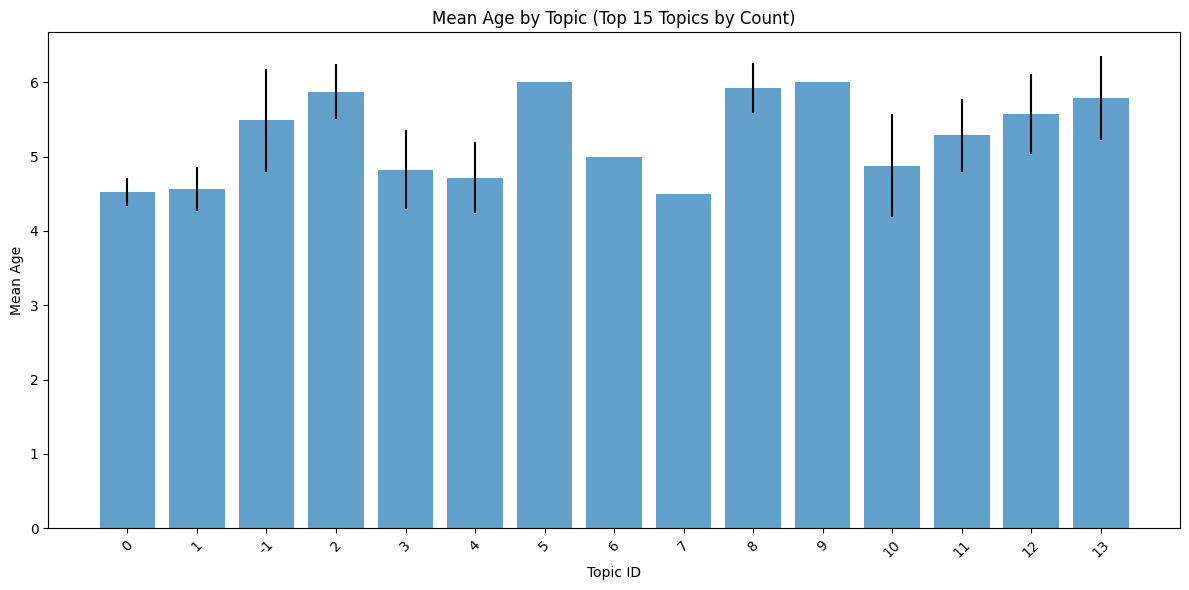

In [ ]:
# Create topic-age analysis
topic_age_df = event_metadata_df[event_metadata_df['target_age'].notna()].copy()

if len(topic_age_df) > 0:
    # Group by topic and calculate age statistics
    topic_age_stats = topic_age_df.groupby('topic').agg({
        'target_age': ['mean', 'std', 'count', 'min', 'max']
    }).reset_index()
    
    topic_age_stats.columns = ['topic', 'mean_age', 'std_age', 'count', 'min_age', 'max_age']
    topic_age_stats = topic_age_stats.sort_values('count', ascending=False)
    
    print("Topic-Age Statistics:")
    print(topic_age_stats.head(20))
    
    # Visualize topic-age relationship
    import matplotlib.pyplot as plt
    import seaborn as sns
    
    plt.figure(figsize=(12, 6))
    top_topics = topic_age_stats.head(15)
    plt.bar(range(len(top_topics)), top_topics['mean_age'], yerr=top_topics['std_age'], alpha=0.7)
    plt.xlabel('Topic ID')
    plt.ylabel('Mean Age')
    plt.title('Mean Age by Topic (Top 15 Topics by Count)')
    plt.xticks(range(len(top_topics)), top_topics['topic'], rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("No age data available for topic-age analysis")


In [ ]:
# Create topic features for age prediction
story_topic_features = []

# Get unique topics once
unique_topics = sorted(event_metadata_df['topic'].unique())

for story_idx in matched_df.index:
    story_events = event_metadata_df[event_metadata_df['story_idx'] == story_idx]
    
    if len(story_events) > 0 and story_events['target_age'].notna().any():
        # Get topic distribution
        topic_counts = Counter(story_events['topic'])
        total_events = len(story_events)
        
        # Create feature vector (topic proportions)
        feature_vector = [topic_counts.get(topic, 0) / total_events for topic in unique_topics]
        
        target_age = story_events['target_age'].iloc[0]  # Should be the same for all events
        
        story_topic_features.append({
            'story_idx': story_idx,
            'target_age': target_age,
            'feature_vector': feature_vector
        })

if len(story_topic_features) > 0:
    features_df = pd.DataFrame(story_topic_features)
    print(f"Created features for {len(features_df)} stories")
    
    # Convert feature vectors to numpy array
    X = np.array(features_df['feature_vector'].tolist())
    y = features_df['target_age'].values
    
    print(f"Feature matrix shape: {X.shape}")
    print(f"Target ages range: {y.min():.1f} - {y.max():.1f}")
else:
    print("No stories with age data for prediction")


Created features for 5 stories
Feature matrix shape: (5, 19)
Target ages range: 4.5 - 6.0


In [ ]:
# Try age prediction using topic features
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error, classification_report

if len(story_topic_features) > 5:
    # Convert age to categories for classification
    def age_to_category(age):
        if age < 3:
            return '0-2'
        elif age < 5:
            return '3-4'
        elif age < 7:
            return '5-6'
        elif age < 9:
            return '7-8'
        else:
            return '9+'
    
    # Create age categories
    y_categories = [age_to_category(age) for age in y]
    
    # Split data
    X_train, X_test, y_train, y_test, y_cat_train, y_cat_test = train_test_split(
        X, y, y_categories, test_size=0.3, random_state=42
    )
    
    # Regression model
    rf_reg = RandomForestRegressor(n_estimators=100, random_state=42)
    rf_reg.fit(X_train, y_train)
    y_pred_reg = rf_reg.predict(X_test)
    
    print("Regression Results:")
    print(f"MAE: {mean_absolute_error(y_test, y_pred_reg):.2f}")
    print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_reg)):.2f}")
    print(f"R²: {r2_score(y_test, y_pred_reg):.2f}")
    
    # Classification model
    rf_clf = RandomForestClassifier(n_estimators=100, random_state=42)
    rf_clf.fit(X_train, y_cat_train)
    y_pred_clf = rf_clf.predict(X_test)
    
    print("\nClassification Results:")
    print(classification_report(y_cat_test, y_pred_clf))
    
    # Feature importance (unique_topics defined in previous cell)
    feature_importance = pd.DataFrame({
        'topic': unique_topics,
        'importance': rf_clf.feature_importances_
    }).sort_values('importance', ascending=False)
    
    print("\nTop 10 Most Important Topics for Age Prediction:")
    print(feature_importance.head(10))
    
    # Visualize
    plt.figure(figsize=(10, 6))
    plt.barh(range(10), feature_importance.head(10)['importance'])
    plt.yticks(range(10), feature_importance.head(10)['topic'])
    plt.xlabel('Feature Importance')
    plt.title('Top 10 Topics for Age Prediction')
    plt.tight_layout()
    plt.show()
    
else:
    print(f"Not enough data for train/test split (only {len(story_topic_features)} samples)")


Not enough data for train/test split (only 5 samples)


In [ ]:
# Save results
output_dir = '../output'
os.makedirs(output_dir, exist_ok=True)

# Save matched data with topics
matched_df.to_csv(f'{output_dir}/matched_stories_with_topics.csv', index=False)

# Save topic info
topic_info.to_csv(f'{output_dir}/topic_info.csv', index=False)

# Save event metadata with topics
event_metadata_df.to_csv(f'{output_dir}/events_with_topics.csv', index=False)

# Save tuning results
tuning_results.to_csv(f'{output_dir}/hyperparameter_tuning_results.csv', index=False)

if len(topic_age_df) > 0:
    topic_age_stats.to_csv(f'{output_dir}/topic_age_statistics.csv', index=False)

print(f"Results saved to {output_dir}/")


Results saved to ../output/


## 7. Save Cleaned Transcripts as Separate Text Files


In [ ]:
# Save cleaned transcripts as separate text files
transcripts_dir = '../output/cleaned_transcripts'
os.makedirs(transcripts_dir, exist_ok=True)

# Function to sanitize filename
def sanitize_filename(filename):
    """Remove invalid characters from filename"""
    import string
    valid_chars = "-_.() %s%s" % (string.ascii_letters, string.digits)
    filename = ''.join(c for c in filename if c in valid_chars)
    filename = filename.replace(' ', '_')  # Replace spaces with underscores
    return filename[:100]  # Limit length

# Save all transcripts (use youtube_df if we want all, or matched_df if only matched)
# For all transcripts, ensure they're cleaned
if 'cleaned_transcript' not in youtube_df.columns:
    youtube_df['cleaned_transcript'] = youtube_df['cleaned_subtitles'].apply(clean_transcript)

# Save each transcript from all YouTube stories
saved_files = []
for idx, row in youtube_df.iterrows():
    if 'cleaned_transcript' in row and pd.notna(row['cleaned_transcript']) and len(str(row['cleaned_transcript']).strip()) > 0:
        # Get story title for filename
        title = row.get('title', f'story_{idx}')
        filename = sanitize_filename(str(title)) + '.txt'
        filepath = os.path.join(transcripts_dir, filename)
        
        # Write transcript to file
        with open(filepath, 'w', encoding='utf-8') as f:
            f.write(row['cleaned_transcript'])
        
        saved_files.append({
            'index': idx,
            'title': title,
            'filename': filename
        })

print(f"Saved {len(saved_files)} cleaned transcripts to {transcripts_dir}/")
print("\nSample saved files:")
for file_info in saved_files[:10]:
    print(f"  - {file_info['filename']}")


In [16]:
# Visualize topics
try:
    fig = best_model.visualize_topics()
    fig.write_html(f'{output_dir}/topic_visualization.html')
    print(f"Topic visualization saved to {output_dir}/topic_visualization.html")
except Exception as e:
    print(f"Could not create topic visualization: {e}")

try:
    fig = best_model.visualize_barchart(top_n_topics=15)
    fig.write_html(f'{output_dir}/topic_barchart.html')
    print(f"Topic barchart saved to {output_dir}/topic_barchart.html")
except Exception as e:
    print(f"Could not create topic barchart: {e}")


Topic visualization saved to ../output/topic_visualization.html
Topic barchart saved to ../output/topic_barchart.html
